# Policy Tuning Report

Audits the Optuna tuning artifacts in `artifacts/` for **one dataset**. Each artifact covers one
`(dataset, target, split seed)` and records the complete trial log — every config's objective, full
ranking-metric block, and wall time — not just the winner.

**To report a different dataset**: copy this notebook and change `DATASET` in the config cell below.
Nothing else is dataset-specific. One notebook = one dataset.

**Protocol being audited.** For each split seed, an inner validation split is carved from the task's
*outer train* frame (25%, seeded `split_seed + 1000`); test data never enters tuning. Each policy is
searched with a seeded `TPESampler`, and the objective is
`macro_by_user_group_mean.ndcg@10` on that inner split.

**What this report answers**

1. Which single hyperparameter set should be frozen across seeds, and what does freezing it cost?
   → `panel_shared_config`
2. Is the tuned roster a sound reference for policy-ranking agreement, or are some policies tied
   within seed noise? → `panel_policy_ordering`

Everything is read-only. `panel_shared_config` prints a config block for review; it writes nothing.

## 1. Setup

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 200)


def find_repo_root(start: Path | None = None) -> Path:
    path = (start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "pyproject.toml").exists() and candidate.name == "beyond-click-sim":
            return candidate
    raise RuntimeError("Could not find beyond-click-sim repo root")


REPO_ROOT = find_repo_root()

try:
    from beyond_click_sim.analysis import policy_tuning_report as report
except ImportError:  # notebook running outside the installed venv
    sys.path.insert(0, str(REPO_ROOT / "src"))
    from beyond_click_sim.analysis import policy_tuning_report as report

from beyond_click_sim.tasks.policy_tuning import POLICY_CLASSES

# ---------------------------------------------------------------- config ---
DATASET = "ml-1m"           # copy this notebook and change this line
ARTIFACTS_DIR = None        # None -> <repo root>/artifacts
SEEDS = None                # None -> every seed found on disk
SETUP = None                # None -> whatever the artifacts carry
TARGET = None               # None -> whatever the artifacts carry

EXPECTED_POLICIES = tuple(POLICY_CLASSES)   # flags partial artifacts
EXPECTED_SEEDS = None                       # None -> contiguous range of what's present
MIN_SEEDS_FOR_SHARED_CONFIG = None          # None -> simple majority of seeds
OBJECTIVE_COLUMN = "value"                  # any numeric column of `arts.trials`

SAVE_FIGS = False
FIG_DIR = REPO_ROOT / "outputs" / "figures" / "policy_tuning"
# ---------------------------------------------------------------------------

report.apply_style()
print(f"REPO_ROOT: {REPO_ROOT}")
print(f"DATASET:   {DATASET}")

/Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


REPO_ROOT: /Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim
DATASET:   ml-1m


## 2. Load

`arts` holds five flat tables: `files`, `identity`, `selection`, `trials`, plus the resolved
`search_spaces`. `trials` is the complete one — one row per (seed, policy, trial), carrying every
field present in the artifact.

In [2]:
arts = report.load_tuning_artifacts(
    DATASET,
    ARTIFACTS_DIR,
    seeds=SEEDS,
    setup=SETUP,
    target=TARGET,
)
arts

TuningArtifacts(dataset='ml-1m', seeds=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9], policies=['ALSPolicy', 'BPRPolicy', 'ItemKNNPolicy', 'LightGCNTorchPolicy', 'PopularityPolicy', 'RandomPolicy'], trials=540, space_source='live_module')

### Per-policy tables — build your own panels from here

One table per policy: `arts.trials` restricted to that policy, with unused parameter columns dropped
and the `param__` prefix stripped. Nothing is aggregated, so every field from the artifact is
reachable. Column prefixes: `mugm__` = `ranking.macro_by_user_group_mean`, `mbg__` =
`ranking.macro_by_group`, `*_cond` = the same metric averaged over only those users who had at least
one positive in their recommended list.

In [3]:
tables = report.per_policy_tables(arts)

for name, table in tables.items():
    print(f"{name:24s} {table.shape[0]:4d} trials x {table.shape[1]} columns")

# Example: everything recorded for one policy.
tables[arts.tuned_policies[0]].head()

ALSPolicy                 240 trials x 68 columns
BPRPolicy                 120 trials x 69 columns
ItemKNNPolicy              40 trials x 66 columns
LightGCNTorchPolicy       120 trials x 68 columns
PopularityPolicy           10 trials x 65 columns
RandomPolicy               10 trials x 65 columns


,seed,trial,state,config_key,value,tuned,val_objective,n_eval_users,alpha,n_factors,regularization,fit_recommend_seconds,mean_hit_rate,n_recommendations,n_users,mugm__groups_with_score_ties,mugm__groups_with_score_ties_fraction,mugm__groups_with_size_lte@1,mugm__groups_with_size_lte@10,mugm__groups_with_size_lte@3,mugm__groups_with_size_lte@5,mugm__groups_without_positive,mugm__hit_rate@1,mugm__hit_rate@10,mugm__hit_rate@3,mugm__hit_rate@5,mugm__n,mugm__n_groups,mugm__n_positive,mugm__n_users,mugm__ndcg@1,mugm__ndcg@10,mugm__ndcg@3,mugm__ndcg@5,mugm__tie_policy,mbg__groups_with_score_ties,mbg__groups_with_score_ties_fraction,mbg__groups_with_size_lte@1,mbg__groups_with_size_lte@10,mbg__groups_with_size_lte@3,mbg__groups_with_size_lte@5,mbg__groups_without_positive,mbg__hit_rate@1,mbg__hit_rate@10,mbg__hit_rate@3,mbg__hit_rate@5,mbg__n,mbg__n_groups,mbg__n_positive,mbg__ndcg@1,mbg__ndcg@10,mbg__ndcg@3,mbg__ndcg@5,mbg__tie_policy,ranking_ks,ranking_tie_policy,dup_index,is_duplicate,is_selected,is_best_in_seed,mugm__hit_rate@1_cond,mugm__hit_rate@10_cond,mugm__hit_rate@3_cond,mugm__hit_rate@5_cond,mugm__ndcg@1_cond,mugm__ndcg@10_cond,mugm__ndcg@3_cond,mugm__ndcg@5_cond
0,0,0,complete,"{""alpha"": 10.0, ""n_factors"": 16, ""regularizati...",0.505701,True,0.516237,6040,10.0,16.0,0.10,5.002995,0.197747,60360,6036,0,0.0,0,6036,0,0,1216,0.265573,0.798542,0.533632,0.665507,60360,6036,11936,6036,0.265573,0.505701,0.304859,0.369197,average,0,0.0,0,6036,0,0,1216,0.265573,0.798542,0.533632,0.665507,60360,6036,11936,0.265573,0.505701,0.304859,0.369197,average,"(1, 3, 5, 10)",average,0,False,False,False,0.332573,1.0,0.668257,0.833402,0.332573,0.633280,0.381769,0.462339
1,0,1,complete,"{""alpha"": 5.0, ""n_factors"": 16, ""regularizatio...",0.511716,True,0.516237,6040,5.0,16.0,0.10,5.050670,0.202667,60360,6036,0,0.0,0,6036,0,0,1199,0.276011,0.801359,0.541252,0.666335,60360,6036,12233,6036,0.276011,0.511716,0.309806,0.373106,average,0,0.0,0,6036,0,0,1199,0.276011,0.801359,0.541252,0.666335,60360,6036,12233,0.276011,0.511716,0.309806,0.373106,average,"(1, 3, 5, 10)",average,0,False,False,False,0.344428,1.0,0.675419,0.831507,0.344428,0.638561,0.386601,0.465592
2,0,2,complete,"{""alpha"": 5.0, ""n_factors"": 32, ""regularizatio...",0.516237,True,0.516237,6040,5.0,32.0,0.01,5.168507,0.202137,60360,6036,0,0.0,0,6036,0,0,1131,0.271703,0.812624,0.553181,0.676938,60360,6036,12201,6036,0.271703,0.516237,0.310810,0.376077,average,0,0.0,0,6036,0,0,1131,0.271703,0.812624,0.553181,0.676938,60360,6036,12201,0.271703,0.516237,0.310810,0.376077,average,"(1, 3, 5, 10)",average,0,False,True,True,0.334353,1.0,0.680734,0.833028,0.334353,0.635271,0.382477,0.462793
3,0,3,complete,"{""alpha"": 10.0, ""n_factors"": 16, ""regularizati...",0.505952,True,0.516237,6040,10.0,16.0,0.01,5.201042,0.197598,60360,6036,0,0.0,0,6036,0,0,1219,0.266070,0.798045,0.532969,0.664679,60360,6036,11927,6036,0.266070,0.505952,0.305209,0.369919,average,0,0.0,0,6036,0,0,1219,0.266070,0.798045,0.532969,0.664679,60360,6036,11927,0.266070,0.505952,0.305209,0.369919,average,"(1, 3, 5, 10)",average,0,False,False,False,0.333403,1.0,0.667843,0.832884,0.333403,0.633989,0.382446,0.463532
4,0,4,complete,"{""alpha"": 2.0, ""n_factors"": 16, ""regularizatio...",0.504471,True,0.516237,6040,2.0,16.0,0.10,5.647846,0.200199,60360,6036,0,0.0,0,6036,0,0,1239,0.268555,0.794732,0.535951,0.658383,60360,6036,12084,6036,0.268555,0.504471,0.305735,0.366841,average,0,0.0,0,6036,0,0,1239,0.268555,0.794732,0.535951,0.658383,60360,6036,12084,0.268555,0.504471,0.305735,0.366841,average,"(1, 3, 5, 10)",average,0,False,False,False,0.337920,1.0,0.674380,0.828434,0.337920,0.634769,0.384703,0.461592


In [4]:
# The full column list, for writing custom panels.
list(arts.trials.columns)

['seed',
 'policy',
 'trial',
 'state',
 'error',
 'config_key',
 'value',
 'tuned',
 'val_objective',
 'n_eval_users',
 'param__alpha',
 'param__n_factors',
 'param__regularization',
 'fit_recommend_seconds',
 'mean_hit_rate',
 'n_recommendations',
 'n_users',
 'mugm__groups_with_score_ties',
 'mugm__groups_with_score_ties_fraction',
 'mugm__groups_with_size_lte@1',
 'mugm__groups_with_size_lte@10',
 'mugm__groups_with_size_lte@3',
 'mugm__groups_with_size_lte@5',
 'mugm__groups_without_positive',
 'mugm__hit_rate@1',
 'mugm__hit_rate@10',
 'mugm__hit_rate@3',
 'mugm__hit_rate@5',
 'mugm__n',
 'mugm__n_groups',
 'mugm__n_positive',
 'mugm__n_users',
 'mugm__ndcg@1',
 'mugm__ndcg@10',
 'mugm__ndcg@3',
 'mugm__ndcg@5',
 'mugm__tie_policy',
 'mbg__groups_with_score_ties',
 'mbg__groups_with_score_ties_fraction',
 'mbg__groups_with_size_lte@1',
 'mbg__groups_with_size_lte@10',
 'mbg__groups_with_size_lte@3',
 'mbg__groups_with_size_lte@5',
 'mbg__groups_without_positive',
 'mbg__hit_rate@

## 3. Completeness and provenance

Gate for everything below: is this a coherent, complete set of artifacts? The last three rows check
invariants that the evaluation code guarantees structurally — a failure there means something
upstream changed, not that a run went badly.

In [5]:
completeness = report.panel_completeness(
    arts,
    expected_policies=EXPECTED_POLICIES,
    expected_seeds=EXPECTED_SEEDS,
)

dataset=ml-1m  dir=/Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim/artifacts
objective=macro_by_user_group_mean.ndcg@10  space_source=live_module
10 artifact(s), 540 trial rows



,check,status,detail
0,schema_version,PASS,"found [1], expected 1"
1,single setup,PASS,['preference']
2,single target,PASS,['target_like_ge4']
3,single optuna_version,PASS,['4.9.0']
4,seed coverage,PASS,"10 present [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
5,policy roster complete,PASS,"roster=['RandomPolicy', 'PopularityPolicy', 'I..."
6,search_spaces_sha256 consistent,PASS,1 distinct hash(es)
7,search space matches live SEARCH_SPACES,PASS,grid sizes are exact
8,identity constant across seeds,PASS,only split_seed varies
9,git_commit recorded,WARN,10/10 artifacts have no git_commit — these car...


,seed,file,setup,target,n_policies,generated_at,git_commit,optuna_version
0,0,ml-1m_target_like_ge4_seed0.json,preference,target_like_ge4,6,2026-08-08T13:17:57Z,None,4.9.0
1,1,ml-1m_target_like_ge4_seed1.json,preference,target_like_ge4,6,2026-08-08T13:20:07Z,None,4.9.0
2,2,ml-1m_target_like_ge4_seed2.json,preference,target_like_ge4,6,2026-08-08T13:22:15Z,None,4.9.0
3,3,ml-1m_target_like_ge4_seed3.json,preference,target_like_ge4,6,2026-08-08T13:22:21Z,None,4.9.0
4,4,ml-1m_target_like_ge4_seed4.json,preference,target_like_ge4,6,2026-08-08T13:40:41Z,None,4.9.0
5,5,ml-1m_target_like_ge4_seed5.json,preference,target_like_ge4,6,2026-08-08T13:41:39Z,None,4.9.0
6,6,ml-1m_target_like_ge4_seed6.json,preference,target_like_ge4,6,2026-08-08T13:40:48Z,None,4.9.0
7,7,ml-1m_target_like_ge4_seed7.json,preference,target_like_ge4,6,2026-08-08T13:41:34Z,None,4.9.0
8,8,ml-1m_target_like_ge4_seed8.json,preference,target_like_ge4,6,2026-08-08T13:41:44Z,None,4.9.0
9,9,ml-1m_target_like_ge4_seed9.json,preference,target_like_ge4,6,2026-08-08T13:41:41Z,None,4.9.0


## 4. Search coverage

`TPESampler` resamples configs it has already tried, so the trial budget overstates the search.
Coverage is the fraction of the grid a seed actually evaluated.

This panel governs how the stability panels below may be read: a seed that "chose differently" is
only evidence that the optimum moved if that seed actually evaluated the other seed's winner. Blank
cells in the heatmaps are unknown, not bad.

,policy,n_trials,grid_size,unique_min,unique_max,coverage_min,coverage_max,duplicate_fraction
0,ALSPolicy,240,24,9,13,0.375000,0.541667,0.550000
1,BPRPolicy,120,6,4,6,0.666667,1.000000,0.575000
2,ItemKNNPolicy,40,4,2,3,0.500000,0.750000,0.375000
3,LightGCNTorchPolicy,120,6,5,6,0.833333,1.000000,0.558333
4,PopularityPolicy,10,1,1,1,1.000000,1.000000,0.000000
5,RandomPolicy,10,1,1,1,1.000000,1.000000,0.000000


,policy,seed,n_trials,n_complete,n_unique_configs,grid_size,coverage,n_duplicate_trials,duplicate_fraction
0,ALSPolicy,0,24,24,12,24,0.500000,12,0.500000
1,ALSPolicy,1,24,24,10,24,0.416667,14,0.583333
2,ALSPolicy,2,24,24,9,24,0.375000,15,0.625000
3,ALSPolicy,3,24,24,11,24,0.458333,13,0.541667
4,ALSPolicy,4,24,24,10,24,0.416667,14,0.583333
5,ALSPolicy,5,24,24,12,24,0.500000,12,0.500000
6,ALSPolicy,6,24,24,9,24,0.375000,15,0.625000
7,ALSPolicy,7,24,24,10,24,0.416667,14,0.583333
8,ALSPolicy,8,24,24,12,24,0.500000,12,0.500000
9,ALSPolicy,9,24,24,13,24,0.541667,11,0.458333


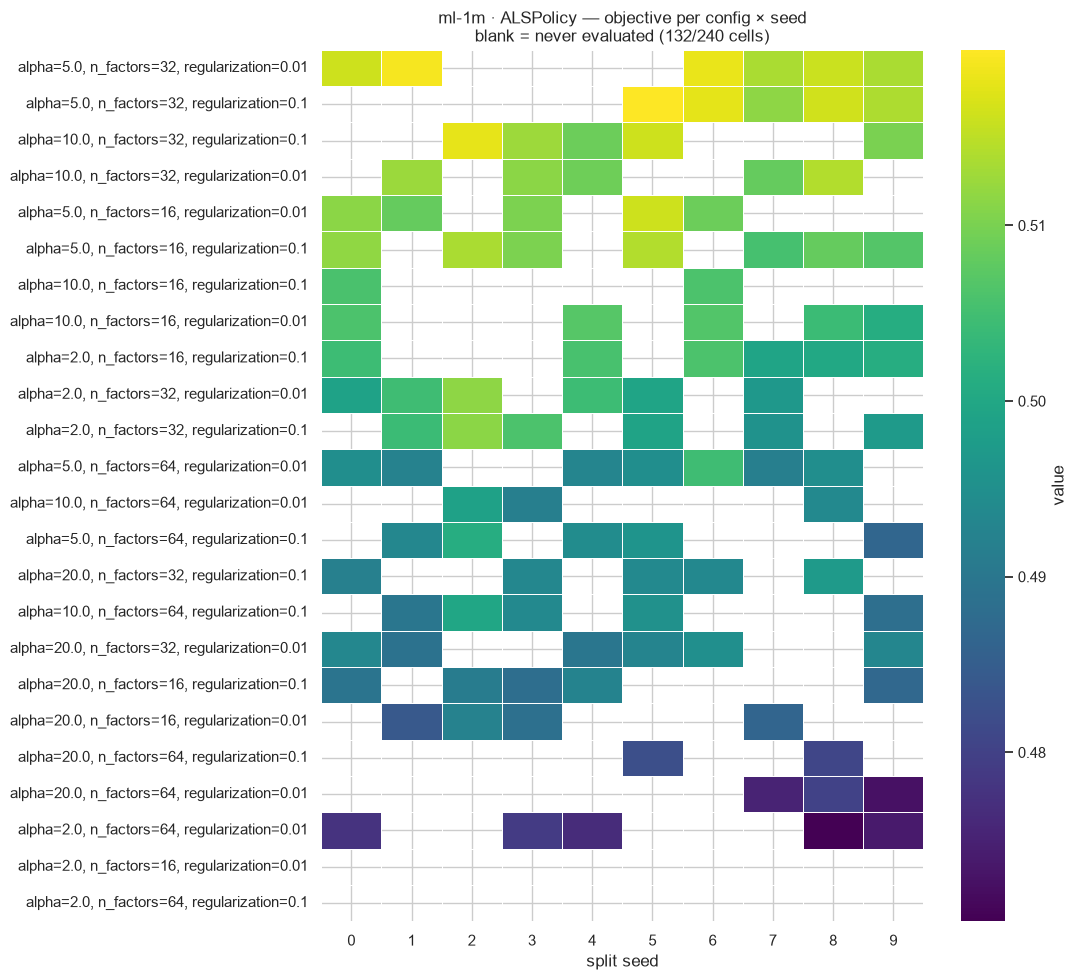

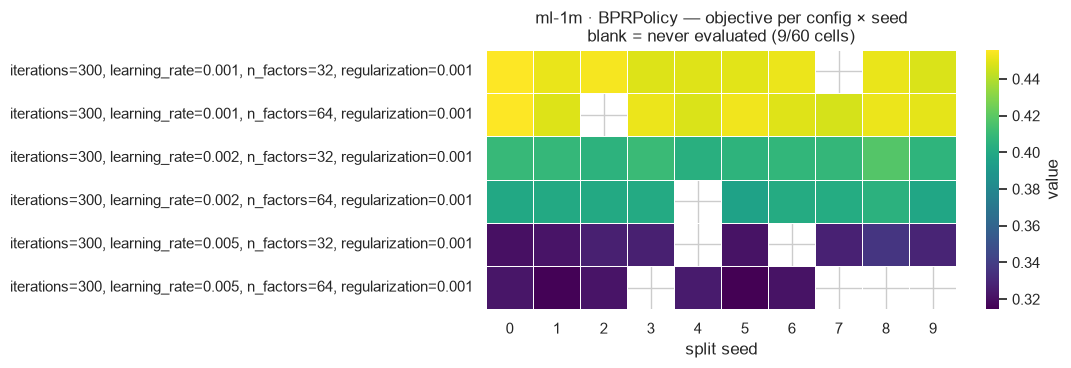

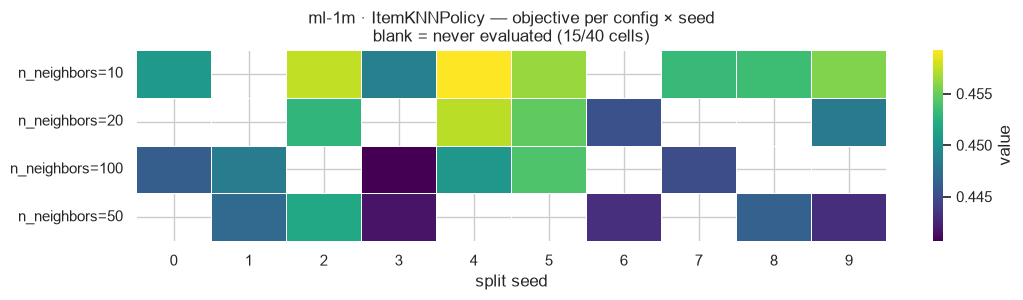

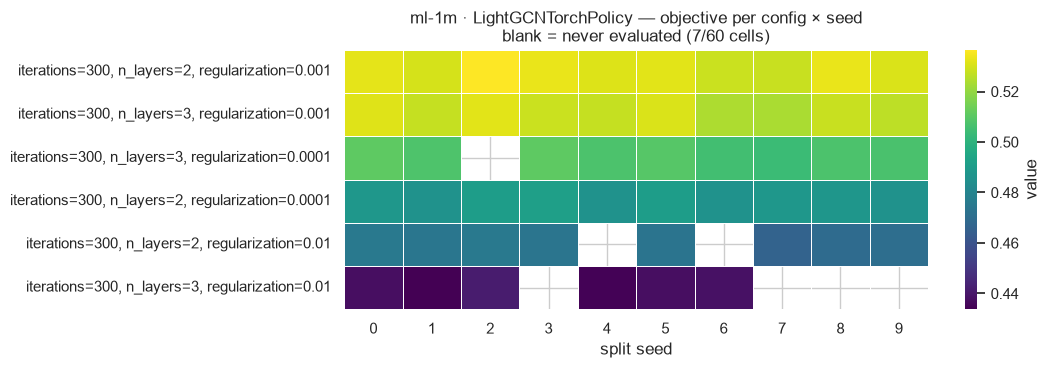

In [6]:
coverage = report.panel_search_coverage(arts, objective_column=OBJECTIVE_COLUMN)

## 5. Determinism

The sampler's duplicate trials are a free reproducibility test: with a fixed `policy_seed`,
re-fitting the same config within the same seed must reproduce its objective exactly.

`deviation_over_sd` is the ratio of that re-fit deviation to the policy's own spread across split
seeds. Approaching 1 means re-running the fit moves the objective about as much as changing the data
split does, so part of the apparent per-seed spread is run-to-run noise rather than signal.

In [7]:
determinism = report.panel_determinism(arts, objective_column=OBJECTIVE_COLUMN)

,policy,n_repeated_configs,n_repeat_trials,max_abs_deviation,best_sd_across_seeds,deviation_over_sd,status
0,ALSPolicy,42,132,0.000000,0.003402,0.000000,PASS (bit-identical)
1,BPRPolicy,34,69,0.002167,0.002596,0.834638,FAIL (nondeterministic)
2,ItemKNNPolicy,13,15,0.000000,0.004521,0.000000,PASS (bit-identical)
3,LightGCNTorchPolicy,37,67,0.000004,0.002541,0.001764,FAIL (nondeterministic)
4,PopularityPolicy,0,0,NaN,0.002916,NaN,no repeats
5,RandomPolicy,0,0,NaN,0.001294,NaN,no repeats


Configs that did NOT reproduce:


,policy,seed,config_key,count,min,max,deviation
0,BPRPolicy,0,"{""iterations"": 300, ""learning_rate"": 0.001, ""n...",3,0.454221,0.456388,0.002167
1,BPRPolicy,6,"{""iterations"": 300, ""learning_rate"": 0.002, ""n...",2,0.398582,0.400645,0.002063
2,BPRPolicy,1,"{""iterations"": 300, ""learning_rate"": 0.002, ""n...",2,0.397925,0.399950,0.002024
3,BPRPolicy,8,"{""iterations"": 300, ""learning_rate"": 0.005, ""n...",3,0.336129,0.337981,0.001852
4,BPRPolicy,1,"{""iterations"": 300, ""learning_rate"": 0.001, ""n...",4,0.449522,0.450927,0.001405
5,BPRPolicy,3,"{""iterations"": 300, ""learning_rate"": 0.005, ""n...",3,0.325483,0.326748,0.001264
6,BPRPolicy,0,"{""iterations"": 300, ""learning_rate"": 0.005, ""n...",4,0.318943,0.320184,0.001241
7,BPRPolicy,3,"{""iterations"": 300, ""learning_rate"": 0.002, ""n...",3,0.400088,0.401293,0.001205
8,BPRPolicy,1,"{""iterations"": 300, ""learning_rate"": 0.002, ""n...",3,0.407239,0.408440,0.001201
9,BPRPolicy,9,"{""iterations"": 300, ""learning_rate"": 0.002, ""n...",5,0.398033,0.399148,0.001115


## 6. Signal vs noise

Is the hyperparameter effect bigger than the seed-to-seed noise? If the spread across configs within
a seed is no larger than the spread of one fixed config across seeds, the tuner is selecting noise
and its choices carry no information — whatever the search budget.

`best_sd_across_seeds` is computed on the per-seed *maximum*, which is upward-biased by an amount
that grows with how many unique configs that seed happened to evaluate. `modal_sd_across_seeds`, on
one fixed config, is the unbiased noise estimate and is what the verdict uses.

,policy,n_configs,mean_within_seed_range,max_within_seed_range,best_sd_across_seeds,modal_config,modal_n_seeds,modal_sd_across_seeds,range_over_noise,verdict
0,ALSPolicy,22,0.035553,0.046005,0.003402,"alpha=5.0, n_factors=16, regularization=0.1",7,0.003452,10.299088,signal
1,BPRPolicy,6,0.127835,0.138475,0.002517,"iterations=300, learning_rate=0.002, n_factors...",10,0.003999,31.964504,signal
2,ItemKNNPolicy,4,0.006061,0.012693,0.004521,n_neighbors=10,8,0.003548,1.708495,NOISE — selection is a coin flip
3,LightGCNTorchPolicy,6,0.081243,0.096810,0.002541,"iterations=300, n_layers=2, regularization=0.0001",10,0.002126,38.206601,signal
4,PopularityPolicy,1,0.000000,0.000000,0.002916,(defaults),10,0.002916,0.000000,n/a (single config)
5,RandomPolicy,1,0.000000,0.000000,0.001294,(defaults),10,0.001294,0.000000,n/a (single config)


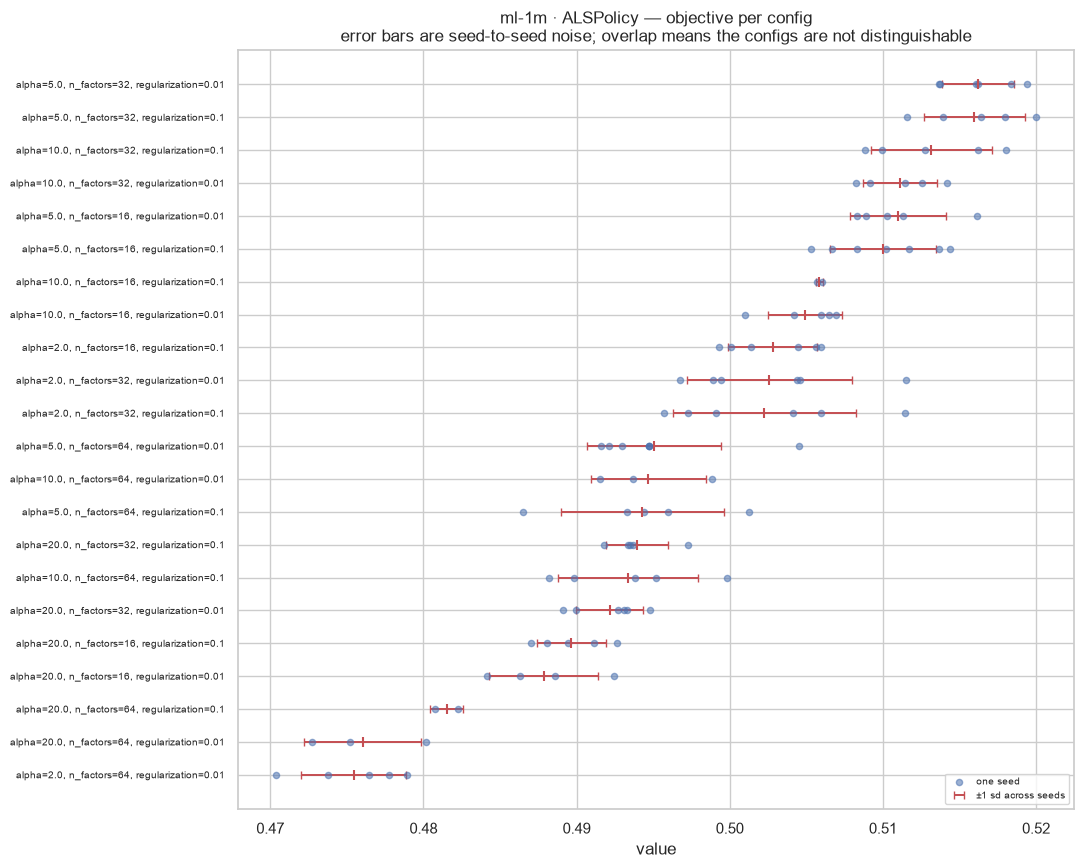

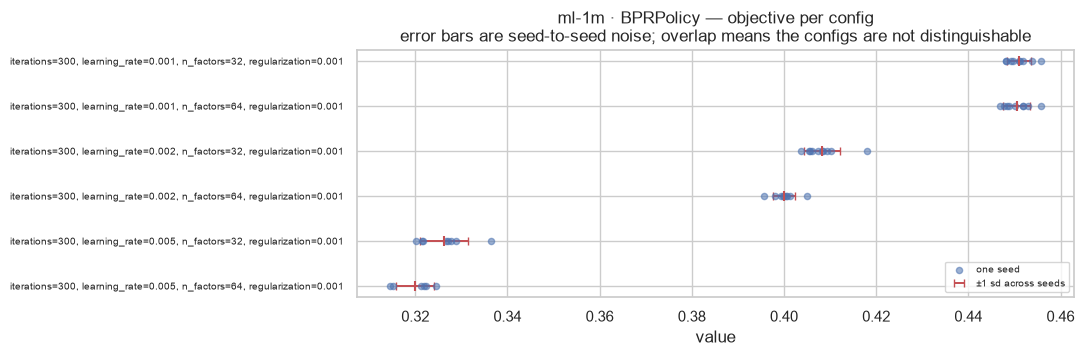

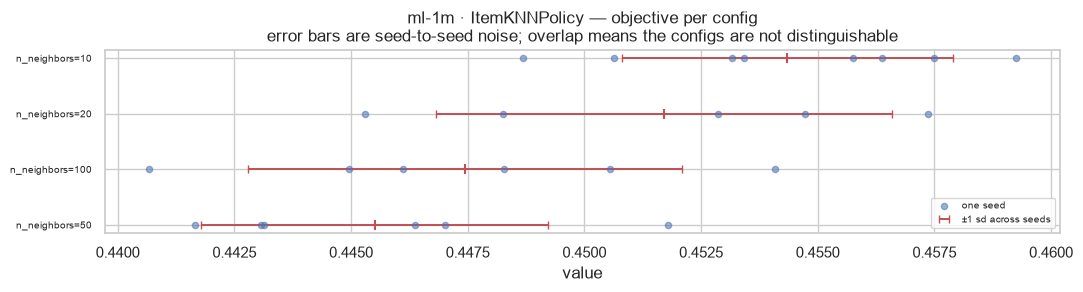

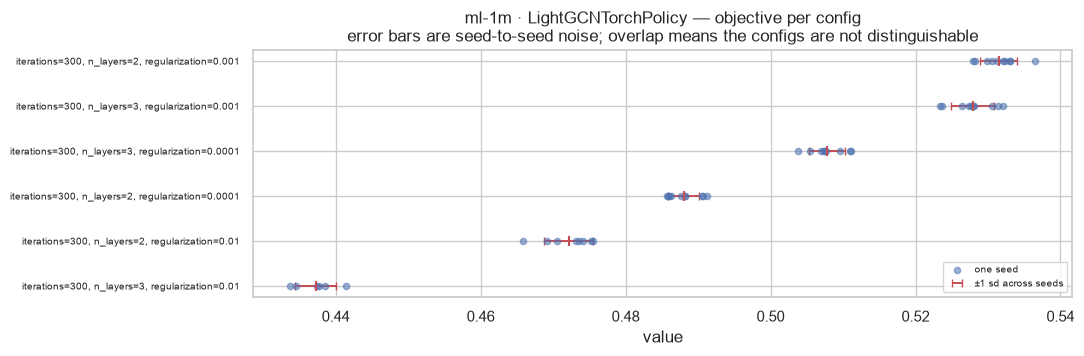

In [8]:
signal = report.panel_signal_vs_noise(arts, objective_column=OBJECTIVE_COLUMN)

## 7. Selection frequency and boundary checks

A selection sitting on the edge of its choice list suggests the search box is misplaced — the tuner
would have gone further if allowed. `policy_tuning.py:77-78` states this rule for the search spaces
themselves.

Parameters pinned to a single value were not searched at all, which is why the recorded trial budget
can exceed the grid size.

In [9]:
frequency = report.panel_selection_frequency(arts)

,policy,param,value,n_seeds_selected,fraction,n_choices,choices,is_pinned,is_boundary,boundary_informative
0,ALSPolicy,n_factors,32.000,10,1.0,3,"(16, 32, 64)",False,False,True
1,ALSPolicy,regularization,0.010,5,0.5,2,"(0.01, 0.1)",False,True,False
2,ALSPolicy,regularization,0.100,5,0.5,2,"(0.01, 0.1)",False,True,False
3,ALSPolicy,alpha,5.000,7,0.7,4,"(2.0, 5.0, 10.0, 20.0)",False,False,True
4,ALSPolicy,alpha,10.000,3,0.3,4,"(2.0, 5.0, 10.0, 20.0)",False,False,True
5,BPRPolicy,n_factors,32.000,6,0.6,2,"(32, 64)",False,True,False
6,BPRPolicy,n_factors,64.000,4,0.4,2,"(32, 64)",False,True,False
7,BPRPolicy,learning_rate,0.001,10,1.0,3,"(0.001, 0.002, 0.005)",False,True,True
8,BPRPolicy,iterations,300.000,10,1.0,1,"(300,)",True,False,False
9,BPRPolicy,regularization,0.001,10,1.0,1,"(0.001,)",True,False,False


Selections on a choice-list edge — the search box may be misplaced (see the note at policy_tuning.py:77-78):


,policy,param,value,n_seeds_selected,fraction,n_choices,choices,is_pinned,is_boundary,boundary_informative
0,BPRPolicy,learning_rate,0.001,10,1.0,3,"(0.001, 0.002, 0.005)",False,True,True
1,ItemKNNPolicy,n_neighbors,10.000,8,0.8,4,"(10, 20, 50, 100)",False,True,True
2,ItemKNNPolicy,n_neighbors,100.000,1,0.1,4,"(10, 20, 50, 100)",False,True,True


Pinned to a single value, i.e. not searched at all:


,policy,param,value
0,BPRPolicy,iterations,300.000
1,BPRPolicy,regularization,0.001
2,LightGCNTorchPolicy,iterations,300.000


## 8. Per-seed parameter stability

How much do the tuner's per-seed choices disagree? Each y-axis shows the *full* choice list, so a
value sitting at the top or bottom is visibly on a boundary. Marker colour is that seed's
`val_objective`, which distinguishes a seed that genuinely preferred a different config from one that
landed elsewhere at effectively the same score.

Read against §4: disagreement is only meaningful where both cells were actually evaluated.

,policy,n_seeds,n_distinct_configs_selected,modal_config,n_seeds_agreeing,agreement_fraction,modal_val_objective_mean
0,ALSPolicy,10,4,"alpha=5.0, n_factors=32, regularization=0.01",4,0.4,0.516922
1,BPRPolicy,10,2,"iterations=300, learning_rate=0.001, n_factors...",6,0.6,0.452454
2,ItemKNNPolicy,10,3,n_neighbors=10,8,0.8,0.454345
3,LightGCNTorchPolicy,10,1,"iterations=300, n_layers=2, regularization=0.001",10,1.0,0.531474
4,PopularityPolicy,10,1,(defaults),10,1.0,0.347172
5,RandomPolicy,10,1,(defaults),10,1.0,0.023508


seed,0,1,2,3,4,5,6,7,8,9
policy,,,,,,,,,,
ALSPolicy,"alpha=5.0, n_factors=32, regularization=0.01","alpha=5.0, n_factors=32, regularization=0.01","alpha=10.0, n_factors=32, regularization=0.1","alpha=10.0, n_factors=32, regularization=0.1","alpha=10.0, n_factors=32, regularization=0.01","alpha=5.0, n_factors=32, regularization=0.1","alpha=5.0, n_factors=32, regularization=0.01","alpha=5.0, n_factors=32, regularization=0.01","alpha=5.0, n_factors=32, regularization=0.1","alpha=5.0, n_factors=32, regularization=0.1"
BPRPolicy,"iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors...","iterations=300, learning_rate=0.001, n_factors..."
ItemKNNPolicy,n_neighbors=10,n_neighbors=100,n_neighbors=10,n_neighbors=10,n_neighbors=10,n_neighbors=10,n_neighbors=20,n_neighbors=10,n_neighbors=10,n_neighbors=10
LightGCNTorchPolicy,"iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001","iterations=300, n_layers=2, regularization=0.001"
PopularityPolicy,(defaults),(defaults),(defaults),(defaults),(defaults),(defaults),(defaults),(defaults),(defaults),(defaults)
RandomPolicy,(defaults),(defaults),(defaults),(defaults),(defaults),(defaults),(defaults),(defaults),(defaults),(defaults)


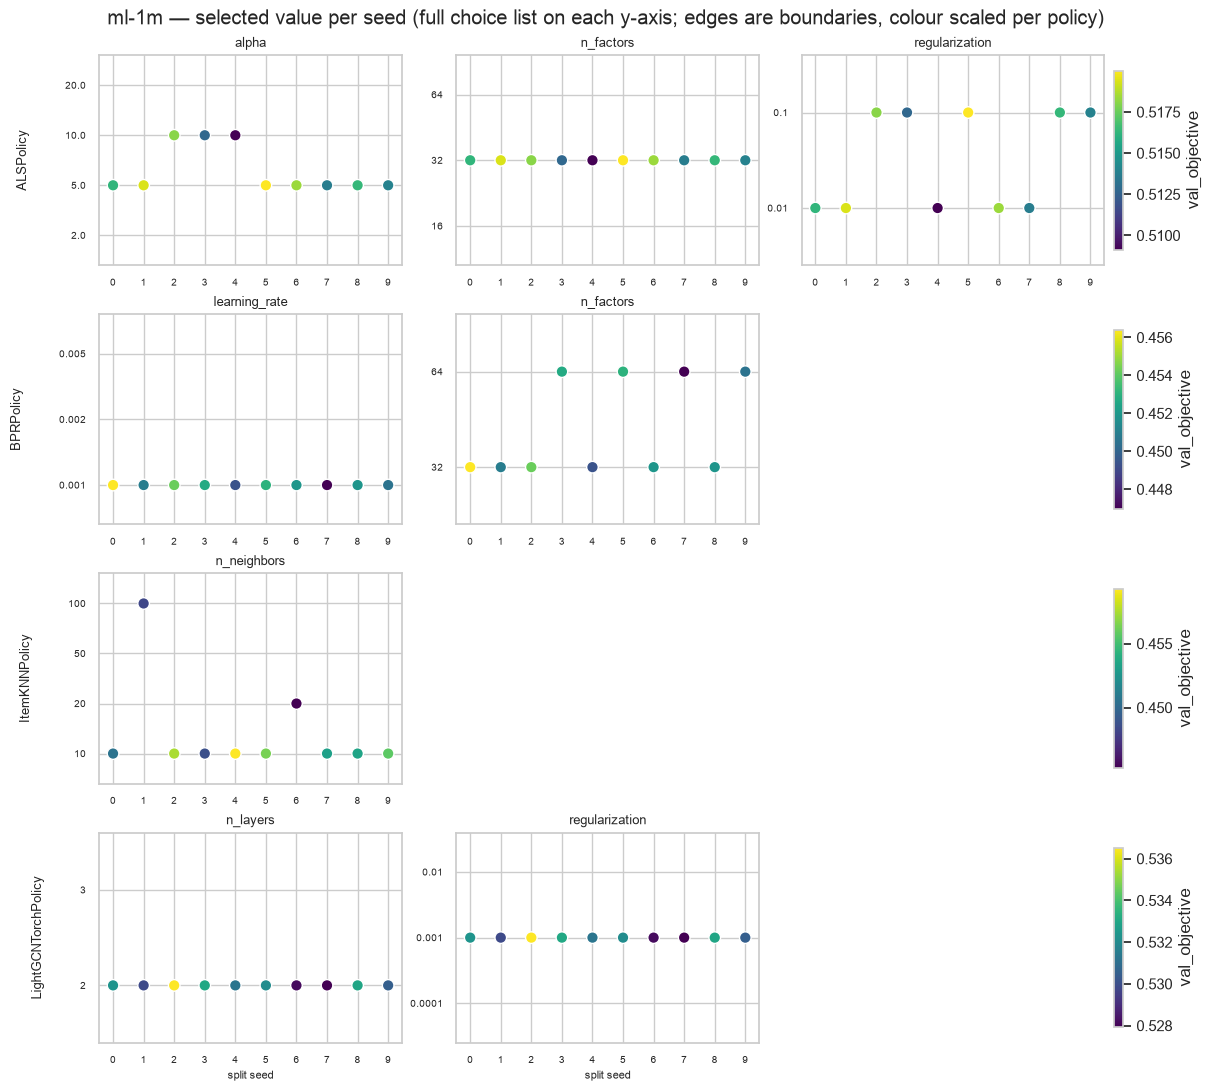

In [10]:
stability = report.panel_param_stability(arts)

## 9. One shared config across seeds

The deliverable: one config per policy, to be used for every seed.

Selection is by **mean rank across seeds** rather than mean objective, since seeds sit at different
overall levels and ranks are invariant to that shift. Ranks are taken against every config evaluated
in that seed, so they stay comparable regardless of which configs clear the eligibility bar.

Eligibility needs care in both directions. Uneven TPE coverage means each config's mean is taken over
a different subset of seeds, so a config sampled once on a lucky seed is not comparable to one
measured everywhere — but demanding full coverage is worse, because a widely-sampled mediocre config
then beats a better one that missed a seed. The default bar is a simple majority, and
`n_seeds_covered` is shown for the winner and every runner-up in the candidates table.

`regret` is measured against the best config *actually evaluated* in each seed: the honest price of
freezing one config versus tuning per seed. Compare it to `sd_across_seeds` — regret inside the noise
band costs nothing real.

**Note on protocol.** This selects a config using all seeds' *inner validation* data. Inner val is
carved from each seed's outer train, so there is no test leakage. It does mean per-seed test results
are no longer fully independent draws, which is a defensible protocol as long as it is stated.

Eligibility: config must be evaluated in >= 5 of 10 seeds. Aggregation: mean rank across all configs tried in each seed.
Because TPE coverage is uneven, each config's mean is taken over a different subset of seeds — read `n_seeds_covered` alongside `mean_value` before trusting a pick.



,policy,chosen_config,n_eligible_configs,n_configs_seen,eligibility_relaxed,seeds_covered,mean_rank,mean_value,mean_regret,max_regret,sd_across_seeds,regret_within_noise,matches_tuner_choice_in_seeds
0,ALSPolicy,"alpha=5.0, n_factors=32, regularization=0.01",17,22,False,6,1.333333,0.516235,0.000094,0.000300,0.002347,True,4
1,BPRPolicy,"iterations=300, learning_rate=0.001, n_factors...",6,6,False,9,1.333333,0.450470,0.000796,0.003052,0.002913,False,4
2,ItemKNNPolicy,n_neighbors=10,4,4,False,8,1.000000,0.454345,0.000000,0.000000,0.003548,True,8
3,LightGCNTorchPolicy,"iterations=300, n_layers=2, regularization=0.001",6,6,False,10,1.000000,0.531474,0.000000,0.000000,0.002541,True,10
4,PopularityPolicy,(defaults),1,1,False,10,1.000000,0.347172,0.000000,0.000000,0.002916,True,10
5,RandomPolicy,(defaults),1,1,False,10,1.000000,0.023508,0.000000,0.000000,0.001294,True,10



Candidates per policy (chosen config first):


,config_key,policy,config,n_seeds_covered,mean_rank,mean_value,eligible
0,"{""alpha"": 5.0, ""n_factors"": 32, ""regularizatio...",ALSPolicy,"alpha=5.0, n_factors=32, regularization=0.01",6,1.333333,0.516235,True
1,"{""alpha"": 5.0, ""n_factors"": 32, ""regularizatio...",ALSPolicy,"alpha=5.0, n_factors=32, regularization=0.1",5,1.400000,0.515964,True
2,"{""alpha"": 10.0, ""n_factors"": 32, ""regularizati...",ALSPolicy,"alpha=10.0, n_factors=32, regularization=0.1",5,1.800000,0.513156,True
3,"{""alpha"": 10.0, ""n_factors"": 32, ""regularizati...",ALSPolicy,"alpha=10.0, n_factors=32, regularization=0.01",5,2.200000,0.511110,True
4,"{""alpha"": 5.0, ""n_factors"": 16, ""regularizatio...",ALSPolicy,"alpha=5.0, n_factors=16, regularization=0.01",5,3.000000,0.510981,True
5,"{""alpha"": 5.0, ""n_factors"": 16, ""regularizatio...",ALSPolicy,"alpha=5.0, n_factors=16, regularization=0.1",7,3.428571,0.510025,True
6,"{""alpha"": 10.0, ""n_factors"": 16, ""regularizati...",ALSPolicy,"alpha=10.0, n_factors=16, regularization=0.01",5,4.400000,0.504920,True
7,"{""alpha"": 2.0, ""n_factors"": 32, ""regularizatio...",ALSPolicy,"alpha=2.0, n_factors=32, regularization=0.01",6,5.000000,0.502588,True
8,"{""alpha"": 2.0, ""n_factors"": 16, ""regularizatio...",ALSPolicy,"alpha=2.0, n_factors=16, regularization=0.1",6,5.333333,0.502806,True
9,"{""alpha"": 2.0, ""n_factors"": 32, ""regularizatio...",ALSPolicy,"alpha=2.0, n_factors=32, regularization=0.1",6,5.666667,0.502266,True



Chosen configs (shape matches `selected_params`):
{
  "ALSPolicy": {
    "alpha": 5.0,
    "n_factors": 32,
    "regularization": 0.01
  },
  "BPRPolicy": {
    "iterations": 300,
    "learning_rate": 0.001,
    "n_factors": 64,
    "regularization": 0.001
  },
  "ItemKNNPolicy": {
    "n_neighbors": 10
  },
  "LightGCNTorchPolicy": {
    "iterations": 300,
    "n_layers": 2,
    "regularization": 0.001
  },
  "PopularityPolicy": {},
  "RandomPolicy": {}
}


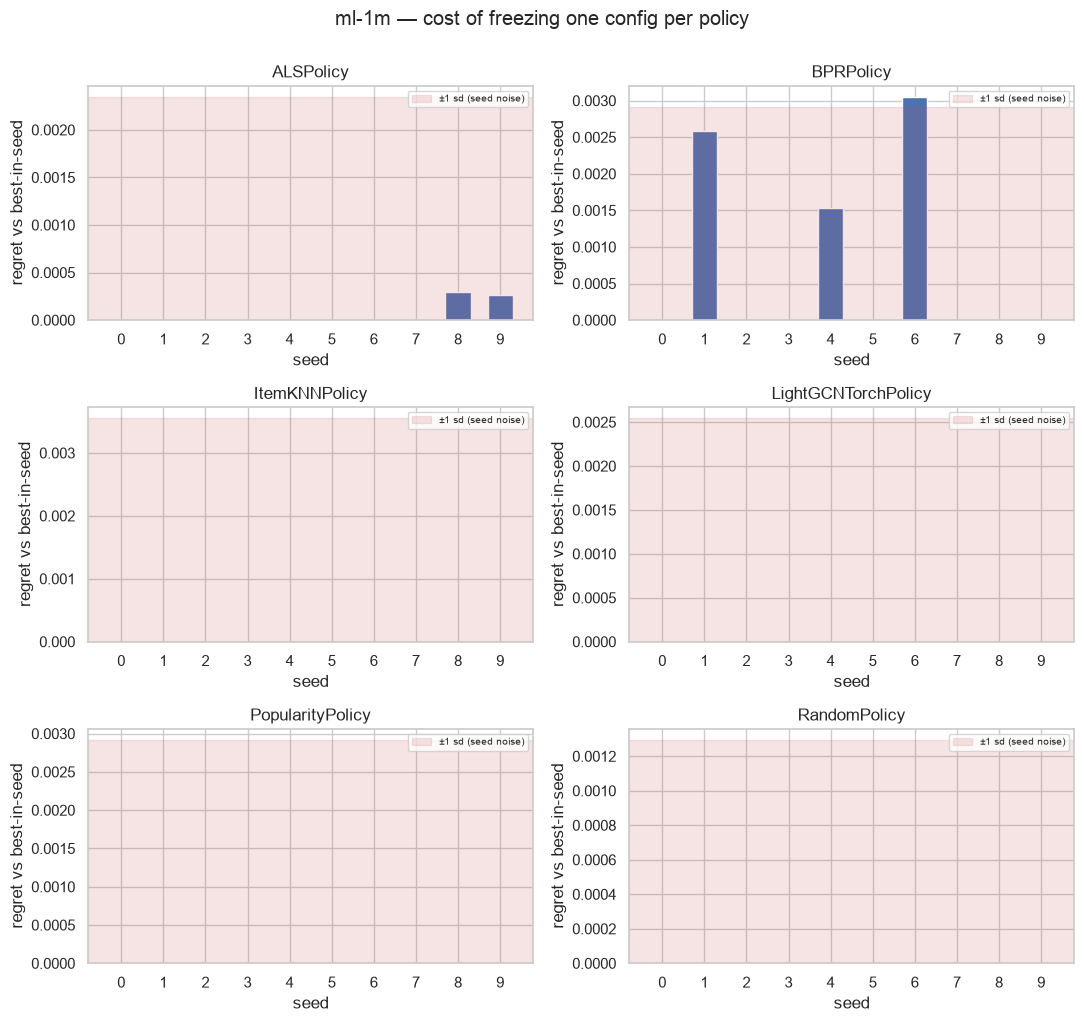

In [11]:
shared = report.panel_shared_config(
    arts,
    min_seeds=MIN_SEEDS_FOR_SHARED_CONFIG,
    objective_column=OBJECTIVE_COLUMN,
)

## 10. Policy ordering stability

This is the input the policy-ranking-agreement experiment rests on: a simulator is scored on
reproducing the ordering of policies under real data. Where two policies are tied within seed noise,
their relative order is a coin flip, and rank correlations computed over them partly measure that
noise rather than simulator quality.

Caveat: this is the ordering on the tuner's *inner validation* split, not the outer test split the
experiment reports. A tie here is a strong hint of a tie there, not proof of one.

,seed,ordering
0,0,LightGCNTorch > ALS > BPR > ItemKNN > Populari...
1,1,LightGCNTorch > ALS > BPR > ItemKNN > Populari...
2,2,LightGCNTorch > ALS > ItemKNN > BPR > Populari...
3,3,LightGCNTorch > ALS > BPR > ItemKNN > Populari...
4,4,LightGCNTorch > ALS > ItemKNN > BPR > Populari...
5,5,LightGCNTorch > ALS > ItemKNN > BPR > Populari...
6,6,LightGCNTorch > ALS > BPR > ItemKNN > Populari...
7,7,LightGCNTorch > ALS > ItemKNN > BPR > Populari...
8,8,LightGCNTorch > ALS > ItemKNN > BPR > Populari...
9,9,LightGCNTorch > ALS > ItemKNN > BPR > Populari...


,policy_a,policy_b,mean_gap,sd_of_paired_gap,abs_gap_over_sd,seeds_a_beats_b,n_seeds,tied
0,BPRPolicy,ItemKNNPolicy,-0.001310,0.005516,0.237540,4,10,True
1,ALSPolicy,LightGCNTorchPolicy,-0.015681,0.004068,3.854623,0,10,False
2,ALSPolicy,ItemKNNPolicy,0.062959,0.006519,9.657245,10,10,False
3,ItemKNNPolicy,LightGCNTorchPolicy,-0.078640,0.004123,19.075700,0,10,False
4,ItemKNNPolicy,PopularityPolicy,0.105662,0.005173,20.424000,10,10,False
5,ALSPolicy,BPRPolicy,0.064269,0.003031,21.207064,10,10,False
6,BPRPolicy,LightGCNTorchPolicy,-0.079950,0.002195,36.426835,0,10,False
7,BPRPolicy,PopularityPolicy,0.104351,0.002426,43.021505,10,10,False
8,ALSPolicy,PopularityPolicy,0.168620,0.002817,59.854686,10,10,False
9,LightGCNTorchPolicy,PopularityPolicy,0.184301,0.002897,63.619527,10,10,False


Pairs tied within seed noise — their relative order is not a reliable reference for ranking agreement:


,policy_a,policy_b,mean_gap,sd_of_paired_gap,seeds_a_beats_b,n_seeds
0,BPRPolicy,ItemKNNPolicy,-0.00131,0.005516,4,10


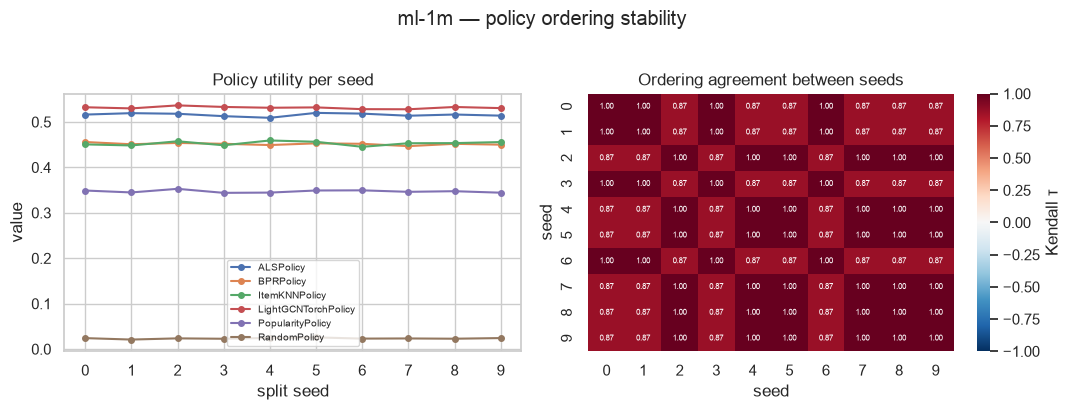

In [12]:
ordering = report.panel_policy_ordering(arts, objective_column=OBJECTIVE_COLUMN)

## 11. Evaluation population

Are all policies scored on the same users? `n_eval_users` is the size of the validation-user frame;
`n_users` is how many users actually received recommendations. Policies that cannot serve users
unseen in inner train are averaged over a strict subset of the users the baselines are averaged over,
so their objectives are not means over identical populations.

,policy,min,max
0,ALSPolicy,6036,6038
1,BPRPolicy,6036,6038
2,ItemKNNPolicy,6036,6038
3,LightGCNTorchPolicy,6036,6038
4,PopularityPolicy,6040,6040
5,RandomPolicy,6040,6040


Policies are NOT scored on the same user set in seed(s) [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] — objectives are means over different populations:


,seed,policy,n_eval_users,n_users,n_groups,n_positive,groups_without_positive,n_recommendations,users_not_served,frac_without_positive
0,0,ALSPolicy,6040,6036,6036,12201,1131,60360,4,0.187376
1,1,ALSPolicy,6040,6037,6037,12174,1096,60370,3,0.181547
2,2,ALSPolicy,6040,6038,6038,12048,1086,60380,2,0.179861
3,3,ALSPolicy,6040,6038,6038,12036,1069,60380,2,0.177045
4,4,ALSPolicy,6040,6037,6037,11959,1114,60370,3,0.184529
5,5,ALSPolicy,6040,6036,6036,12341,1109,60360,4,0.183731
6,6,ALSPolicy,6040,6036,6036,12223,1104,60360,4,0.182903
7,7,ALSPolicy,6040,6038,6038,12147,1116,60380,2,0.184829
8,8,ALSPolicy,6040,6038,6038,12213,1102,60380,2,0.182511
9,9,ALSPolicy,6040,6036,6036,12184,1127,60360,4,0.186713


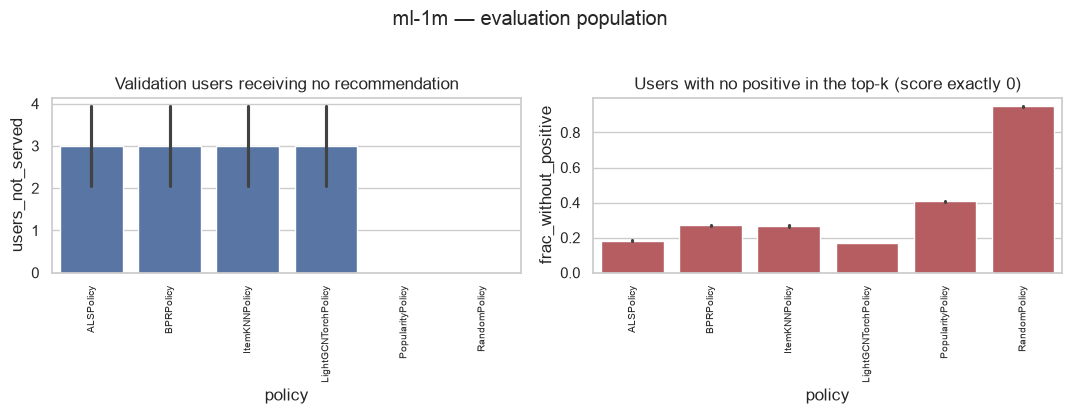

In [13]:
population = report.panel_eval_population(arts)

## 12. Metric decomposition

`groups_with_size_lte@10 == n_groups`: k equals the recommendation list length, so this nDCG has no
retrieval component beyond what the policy put in the list. It is a policy-value metric, not
retrieval nDCG. Two configs can tie on it while differing in how many positives they surfaced versus
how well they ordered them.

Users with no positive in their list score exactly 0, a large zero mass in the mean. The `_cond`
columns restrict the average to users who had at least one — an exact restatement, not an
approximation, given one candidate group per user.

,policy,mugm__ndcg@10,mugm__ndcg@10_cond,mugm__hit_rate@10,mugm__hit_rate@10_cond,mugm__n_positive,frac_users_without_positive
0,ALSPolicy,0.515793,0.631412,0.816896,1.0,12152.6,0.183104
1,BPRPolicy,0.451457,0.617824,0.730727,1.0,9777.1,0.269273
2,ItemKNNPolicy,0.452834,0.616316,0.734736,1.0,9890.0,0.265264
3,LightGCNTorchPolicy,0.531474,0.640446,0.829849,1.0,12785.8,0.170151
4,PopularityPolicy,0.347172,0.585528,0.592930,1.0,7203.1,0.407070
5,RandomPolicy,0.023508,0.462199,0.050844,1.0,323.6,0.949156


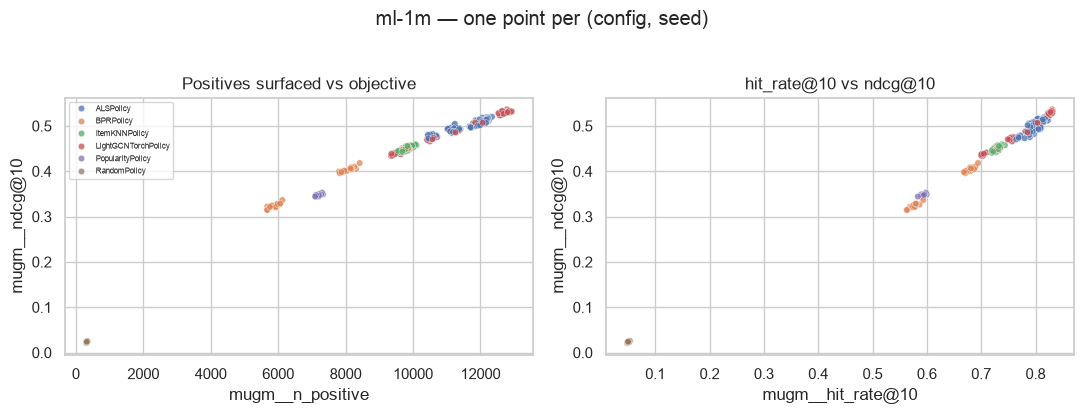

In [14]:
decomposition = report.panel_metric_decomposition(arts)

## 13. Cost

Where the tuning budget went, and how much of it was spent re-evaluating configs already tried.
Sizes any remaining sweep.

Total tuning compute: 29.69 h; spent re-evaluating configs already tried: 15.22 h (51%)


,policy,n_trials,total_seconds,median_seconds,max_seconds,duplicate_seconds,duplicate_fraction
0,ALSPolicy,240,3396.032530,12.233506,33.372096,1794.784372,0.528494
1,BPRPolicy,120,8226.283213,73.881862,91.216877,4896.209443,0.595191
2,ItemKNNPolicy,40,481.507791,11.522689,28.681440,192.978404,0.400779
3,LightGCNTorchPolicy,120,94213.676510,579.056096,1855.789728,47904.966512,0.508471
4,PopularityPolicy,10,42.704005,4.076588,7.799414,0.000000,0.000000
5,RandomPolicy,10,508.720825,68.582306,77.004273,0.000000,0.000000


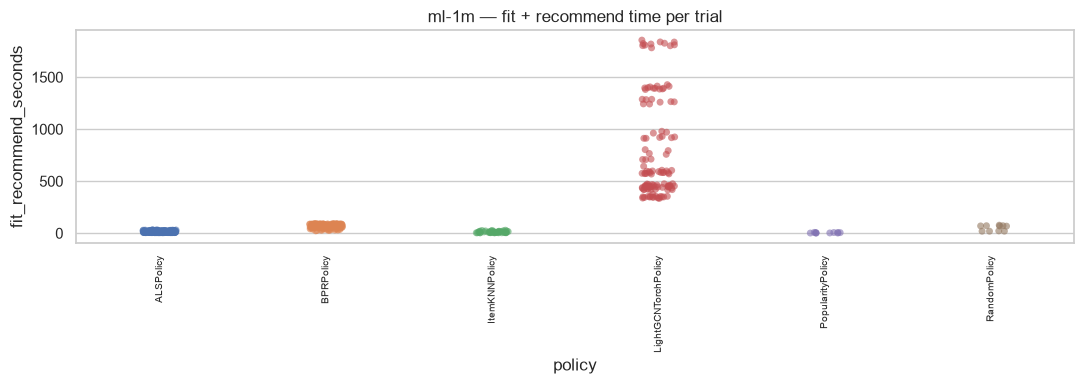

In [15]:
cost = report.panel_cost(arts)

In [16]:
if SAVE_FIGS:
    written = report.save_open_figures(FIG_DIR, prefix=f"{DATASET}_")
    print(f"Wrote {len(written)} figure(s) to {FIG_DIR}")

## Findings

_Fill in after running. The panels above are the evidence; this cell is where the read-out for the
paper goes._